# Эффект использования нового интерфейса интернет-магазина BitMotion Kit

Интернет-магазин BitMotion Kit, в котором продаются геймифицированные товары для тех, кто ведёт здоровый образ жизни, хочет расширить ассортимент товаров. Но перед этим нужно решить одну проблему. Интерфейс онлайн-магазина слишком сложен для пользователей — об этом говорят отзывы.
Чтобы привлечь новых клиентов и увеличить число продаж, владельцы магазина разработали новую версию сайта и протестировали его на части пользователей. По задумке, это решение доказуемо повысит количество пользователей, которые совершат покупку. Ожидаемый эффект - рост конверсии в покупку на 3 п.п. В данной работе анализируются результаты проведенного компанией a/b-теста.

## <a id="content"></a> Оглавление

- [Цель и задачи проекта](#goal)
- [Описание данных](#data_description)
- [Оценка корректности проведения теста](#test_verification)
    - [Вывод по оценке корректности проведения A/B-теста](#test_verification_conclusion)
- [Оценка результатов A/B-тестирования](#test_result)
- [Общий вывод](#conclusion)

## <a id="goal"></a> Цель и задачи проекта
[Вернуться к оглавлению](#content)

Гипотеза команды BitMotion Kit:<br>
- H<sub>0</sub> - конверсия, рассчитанная как доля пользователей, совершивших хотя бы одну покупку в течение семи дней с момента регистрации на сайте, в группе B (новый интерфейс) меньше или равна конверсии в группе А (старый интерфейс)
- H<sub>1</sub> - конверсия в покупку в течение семи дней с момента регистрации в группе B (новый интерфейс) больше, чем в группе А (старый интерфейс)

Нужно провести анализ результатов a/b-теста нового интерфейса интернет-магазина BitMotion Kit:
1) оценить корректность проведения a/b-теста
2) проверить гипотезу с помощью z-теста
3) интерпретировать результаты a/b-теста и дать рекомендацию о целесообразности использования нового интерфейса

## <a id="data_description"></a> Описание данных
[Вернуться к оглавлению](#content)

`ab_test_participants.csv` — таблица участников тестов.
Структура файла:
- `user_id` — идентификатор пользователя;
- `group` — группа пользователя;
- `ab_test` — название теста;
- `device` — устройство, с которого происходила регистрация.

`ab_test_events.zip` — архив с одним csv-файлом, в котором собраны события 2020 года;
Структура файла:
- `user_id` — идентификатор пользователя;
- `event_dt` — дата и время события;
- `event_name` — тип события;
- `details` — дополнительные данные о событии.

Числовые значения в столбце `details`:
- registration (регистрация) — стоимость привлечения клиента;
- purchase (покупка) — стоимость покупки.

## <a id="test_verification"></a> Оценка корректности проведения теста
[Вернуться к оглавлению](#content)

- Загрузим данные и проведем первичный анализ
- Выделим пользователей, участвующих в тесте, и проверим:
   - равномерность распределения пользователей по группам теста,
   - отсутствие пересечений с конкурирующим тестом (нет пользователей, участвующих одновременно в двух тестах).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
from statsmodels.stats.proportion import proportions_ztest

import warnings
warnings.filterwarnings('ignore')

In [2]:
## Загрузим данные датасетов ab_test_participants.csv и ab_test_events.zip
participants = pd.read_csv('datasets/ab_test_participants.csv')
events = pd.read_csv('datasets/ab_test_events.zip',
                     parse_dates=['event_dt'], low_memory=False)

In [3]:
# выведем первые строки датасета ab_test_participants.csv
participants.head()

,user_id,group,ab_test,device
0,0002CE61FF2C4011,B,interface_eu_test,Mac
1,001064FEAAB631A1,B,recommender_system_test,Android
2,001064FEAAB631A1,A,interface_eu_test,Android
3,0010A1C096941592,A,recommender_system_test,Android
4,001E72F50D1C48FA,A,interface_eu_test,Mac


In [4]:
# выведем общую информацию о датасете ab_test_participants.csv
participants.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14525 entries, 0 to 14524
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   user_id  14525 non-null  object
 1   group    14525 non-null  object
 2   ab_test  14525 non-null  object
 3   device   14525 non-null  object
dtypes: object(4)
memory usage: 454.0+ KB


Датасет ab_test_participants.csv содержит данные о пользователях интернет-магазина, участвующих в a/b-тестах.

Данные представлены в четырех столбцах:

- `user_id` - столбец содержит информацию об id пользователя. Данные представляют собой комбинацию букв и цифр, поэтому тип данных `object` подобран верно;
- `group` - столбец содержит информацию о группе теста, в которой состоит пользователь: a или b. Формат хранения данных в столбце object подобран верно, при этом для оптимизации памяти можно перевести данные в формат категориальных данных categorical;
- `ab-test` - столбец содержит информацию об тесте, в котором принимал участие пользователь. Данные представлены в строковом виде, формат хранения данных object подобран верно, при этом для оптимизации памяти можно перевести данные в формат категориальных данных categorical;
- `device` - столбец содержит информацию об устройстве пользователя. Информация данного столбца не требуется для анализа, поэтому он будет удален.
В данных нет пропусков. 
Названия столбцов соответствуют содержанию, имеют удобную для обращения форму записи.

In [5]:
participants['group'] = pd.Categorical(participants['group'])

In [6]:
participants['ab_test'] = pd.Categorical(participants['ab_test'])

In [7]:
participants.drop(labels='device', axis=1, inplace=True)

In [8]:
# проверим результат обработки типов данных и удаления столбца device
participants.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14525 entries, 0 to 14524
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   user_id  14525 non-null  object  
 1   group    14525 non-null  category
 2   ab_test  14525 non-null  category
dtypes: category(2), object(1)
memory usage: 142.2+ KB


Объем памяти датасета `participants` сократился втрое.

In [9]:
# выведем общую информацию датасета ab_test_events.zip
events.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 787286 entries, 0 to 787285
Data columns (total 4 columns):
 #   Column      Non-Null Count   Dtype         
---  ------      --------------   -----         
 0   user_id     787286 non-null  object        
 1   event_dt    787286 non-null  datetime64[ns]
 2   event_name  787286 non-null  object        
 3   details     249022 non-null  object        
dtypes: datetime64[ns](1), object(3)
memory usage: 24.0+ MB


In [10]:
# выведем первые строки датасета ab_test_events.zip для ознакомления
events.head(10)

,user_id,event_dt,event_name,details
0,GLOBAL,2020-12-01 00:00:00,End of Black Friday Ads Campaign,ZONE_CODE15
1,CCBE9E7E99F94A08,2020-12-01 00:00:11,registration,0.0
2,GLOBAL,2020-12-01 00:00:25,product_page,NaN
3,CCBE9E7E99F94A08,2020-12-01 00:00:33,login,NaN
4,CCBE9E7E99F94A08,2020-12-01 00:00:52,product_page,NaN
5,AA346F4D22148024,2020-12-01 00:01:46,registration,-2.0
6,7EF01D0E72AF449D,2020-12-01 00:02:06,registration,-5.0
7,9A6276AD14B14252,2020-12-01 00:02:20,registration,-2.0
8,9B186A3B1A995D36,2020-12-01 00:02:37,registration,-3.5
9,9A6276AD14B14252,2020-12-01 00:02:53,login,NaN


In [11]:
# выведем уникальные значения столбца 'event_name'
events['event_name'].unique()

array(['End of Black Friday Ads Campaign', 'registration', 'product_page',
       'login', 'product_cart', 'purchase',
       'Start of Christmas&New Year Promo',
       'Start of CIS New Year Gift Lottery'], dtype=object)

Датасет ab_test_events.zip содержит данные о действиях пользователей интернет-магазина.

Данные представлены в четырех столбцах:

- `user_id` - столбец содержит информацию об id пользователя. Данные представляют собой комбинацию букв и цифр, поэтому тип данных `object` подобран верно;
- `event_dt` - столбец содержит информацию о дате действий. Формат хранения данных в столбце `datetime64` подобран верно;
- `event_name` - столбец содержит информацию действии пользователя. Данные представлены в строковом виде, формат хранения данных object подобран верно, при этом для оптимизации памяти можно перевести данные в формат категориальных данных categorical;
- `details` - столбец содержит дополнительную информацию к действию пользователя. Информация данного столбца не требуется для анализа, поэтому он будет удален.
В нужных для анализа столбцах нет пропусков. 
Названия столбцов соответствуют содержанию, имеют удобную для обращения форму записи.

In [12]:
# приведем столбец 'event_name' к типу Categorical
events['event_name'] = pd.Categorical(events['event_name'])

In [13]:
# удалим столбец details 
events.drop(labels='details', axis=1, inplace=True)

In [14]:
# проверим результаты обработки типов данных и удаления столбца
events.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 787286 entries, 0 to 787285
Data columns (total 3 columns):
 #   Column      Non-Null Count   Dtype         
---  ------      --------------   -----         
 0   user_id     787286 non-null  object        
 1   event_dt    787286 non-null  datetime64[ns]
 2   event_name  787286 non-null  category      
dtypes: category(1), datetime64[ns](1), object(1)
memory usage: 12.8+ MB


Объем памяти датасета `events` сократился вдвое.

Перейдем к проверке корректности проведения теста. Начнем с проверки пересечения пользователей в конкурирующих тестах.

In [15]:
# Выведем уникальные значения в столбце ab_test
participants['ab_test'].unique()

['interface_eu_test', 'recommender_system_test']
Categories (2, object): ['interface_eu_test', 'recommender_system_test']

In [16]:
# Подсчитаем, сколько пользователей участвуют одновременно в нескольких тестах
participants_intersection = set(participants.loc[participants['ab_test'] == 'interface_eu_test']['user_id']) & set(participants.loc[participants['ab_test'] == 'recommender_system_test']['user_id'])

In [17]:
# Выведем кол-во пользователей, участвующих в нескольких тестах одновременно
print(f'Одновременно в нескольких тестах участвует {len(participants_intersection)} пользователей.')

Одновременно в нескольких тестах участвует 887 пользователей.


В датасете events представлены данные о двух ab-тестах. В обоих тестах участвует 887 пользователей.<br>
Сравним размеры групп теста.

In [18]:
# Выделим из датасета данные для необходимого теста interface_eu_test и удалим строки для пользователей, участвующих в нескольких тестах одновременно
participants_interface = participants.loc[(participants['ab_test'] == 'interface_eu_test') & (~participants['user_id'].isin(list(participants_intersection)))][['user_id', 'group']]

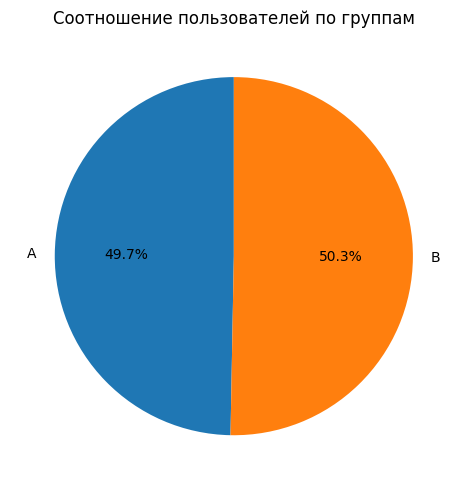

In [19]:
# построим круговую диаграмму соотношения пользователей по группам
participants_interface_count = participants_interface.groupby('group').agg(users_count=('user_id', 'count'))

ax = participants_interface_count.plot(kind='pie',
    y='users_count',
    legend=False,
    figsize=(5, 5),
    autopct='%1.1f%%',
    startangle=90,
    title='Соотношение пользователей по группам')

ax.set_ylabel('')
plt.tight_layout()
plt.show()

In [20]:
participants_interface.groupby('group').agg(users_count=('user_id', 'count'))

,users_count
group,
A,4952
B,5011


Соотношение пользователей по группам теста равномерное - 49.7% или 4952 пользователя в группе A против 50.3% или 5011 пользователей в группе B.

Проанализируем данные о пользовательской активности в датасете `ab_test_events`:

- оставим только события, связанные с участвующими в изучаемом тесте пользователями;

In [21]:
events_interface = events.loc[events['user_id'].isin(participants_interface['user_id'])]

- определим горизонт анализа: рассчитаем время (лайфтайм) совершения события пользователем после регистрации и оставим только те события, которые были выполнены в течение первых семи дней с момента регистрации;

In [22]:
# сформируем вспомогательный датасет с датами регистрации пользователей в интернет-магазине
users_registration_date = events_interface.loc[events_interface['event_name'] == 'registration'][['user_id', 'event_dt']]
users_registration_date.columns = ['user_id', 'registration_dt']

In [23]:
users_registration_date.reset_index(drop=True, inplace=True)

In [24]:
# выведем вспомогательный датасет для проверки
users_registration_date.head()

,user_id,registration_dt
0,5F506CEBEDC05D30,2020-12-06 14:10:01
1,51278A006E918D97,2020-12-06 14:37:25
2,A0C1E8EFAD874D8B,2020-12-06 17:20:22
3,275A8D6254ACF530,2020-12-06 19:36:54
4,0B704EB2DC7FCA4B,2020-12-06 19:42:20


In [25]:
# проверим, что в датасете нет дубликатов user_id
users_registration_date.duplicated(subset=['user_id']).sum()

np.int64(0)

In [26]:
# сформирует новый датасет, в котором к данным о действиях участников теста добавим отдельный столбец с датой регистрации пользователя
events_interface_7days = pd.merge(events_interface, users_registration_date, how='inner', on='user_id')

In [27]:
# добавим столбец lifetime, в котором будет указываться, сколько прошло дней с момента регистрации для каждого последующего действия пользователя
events_interface_7days['lifetime'] = (events_interface_7days['event_dt'] - events_interface_7days['registration_dt']).dt.days

In [28]:
# выведем первые строки датасета для проверки
events_interface_7days.head(10)

,user_id,event_dt,event_name,registration_dt,lifetime
0,5F506CEBEDC05D30,2020-12-06 14:10:01,registration,2020-12-06 14:10:01,0
1,51278A006E918D97,2020-12-06 14:37:25,registration,2020-12-06 14:37:25,0
2,A0C1E8EFAD874D8B,2020-12-06 17:20:22,registration,2020-12-06 17:20:22,0
3,275A8D6254ACF530,2020-12-06 19:36:54,registration,2020-12-06 19:36:54,0
4,0B704EB2DC7FCA4B,2020-12-06 19:42:20,registration,2020-12-06 19:42:20,0
5,8FCA593F7D87FECA,2020-12-06 21:34:19,registration,2020-12-06 21:34:19,0
6,C64851EFACDDDFEB,2020-12-06 22:30:07,registration,2020-12-06 22:30:07,0
7,612F81CFCAD7D062,2020-12-06 22:53:21,registration,2020-12-06 22:53:21,0
8,DD3B49B4AF10F101,2020-12-06 23:32:12,registration,2020-12-06 23:32:12,0
9,9F4B7C7D64845781,2020-12-06 23:42:49,registration,2020-12-06 23:42:49,0


In [29]:
# отфильтруем строки с lifetime больше 7
events_interface_7days = events_interface_7days.loc[events_interface_7days['lifetime'] <= 6]

Оценим достаточность выборки для получения статистически значимых результатов A/B-теста. Заданные параметры:
- базовый показатель конверсии — 30%,
- мощность теста — 80%,
- достоверность теста — 95%.

In [30]:
# Задаём параметры
alpha = 0.05 # Уровень значимости
beta = 0.2 # Ошибка второго рода
power = 1 - beta # Мощность теста
p1 = 0.3 # Базовый уровень конверсии
mde = 0.03  # Минимальный детектируемый эффект
effect_size = proportion_effectsize(p1, p1 + mde)

# Инициализируем класс NormalIndPower
power_analysis = NormalIndPower()

# Рассчитываем размер выборки
sample_size = power_analysis.solve_power(
    effect_size = effect_size,
    power = power,
    alpha = alpha,
    ratio = 1 # Равномерное распределение выборок
)

print(f"Необходимый размер выборки для каждой группы: {int(sample_size)}")

Необходимый размер выборки для каждой группы: 3761


При количестве пользователей в каждой из групп в ~5000 выборки оказались достаточными.

Рассчитаем для каждой группы количество посетителей, сделавших покупку, и общее количество посетителей.

In [31]:
# соединим данные о пользователях, участвующих в тесте интерфейса, с данными об их действиях
events_interface_7days = pd.merge(events_interface_7days, participants_interface, on='user_id')

In [32]:
events_interface_7days.head()

,user_id,event_dt,event_name,registration_dt,lifetime,group
0,5F506CEBEDC05D30,2020-12-06 14:10:01,registration,2020-12-06 14:10:01,0,A
1,51278A006E918D97,2020-12-06 14:37:25,registration,2020-12-06 14:37:25,0,A
2,A0C1E8EFAD874D8B,2020-12-06 17:20:22,registration,2020-12-06 17:20:22,0,B
3,275A8D6254ACF530,2020-12-06 19:36:54,registration,2020-12-06 19:36:54,0,A
4,0B704EB2DC7FCA4B,2020-12-06 19:42:20,registration,2020-12-06 19:42:20,0,B


In [33]:
# подсчитаем общее количество пользователей в группах, количество пользователей, совершивших покупку, и их долю.
events_interface_purchase_share = pd.merge(events_interface_7days.groupby('group').agg(users_count=('user_id', 'nunique')).reset_index(), events_interface_7days.loc[events_interface_7days['event_name'] == 'purchase'].groupby('group').agg(purchasers_count=('user_id', 'nunique')).reset_index(), on='group')
events_interface_purchase_share['purchase_share'] = events_interface_purchase_share['purchasers_count'] / events_interface_purchase_share['users_count']

In [34]:
events_interface_purchase_share.reset_index(inplace=True)

In [35]:
# выведем общее количество пользователей в группах, количество пользователей, совершивших хотя бы одну покупку, и их долю
events_interface_purchase_share

,index,group,users_count,purchasers_count,purchase_share
0,0,A,4952,1377,0.278069
1,1,B,5011,1480,0.295350


Конверсия в покупку в тестовой группе выше чем в контрольной: в тестовой группе конверсия 29.5 %, в контрольной - 27.8 %

### <a id="test_verification_conclusion"></a> Вывод по оценке корректности проведения ab-теста
Данные были оптимизированы для ускорения работы с ними. Проверено соотношение пользователей по группам - распределение равномерное примерно 50 на 50. Оценена достаточность выборки для получения статистически значимых результатов A/B-теста с мощностью теста 80% и достоверностью 95%. Выборки оказались достаточными. Рассчитаны конверсии в покупку: в тестовой группе конверсия 29.5 %, в контрольной - 27.8 %. В предположении, что прирост конверсии является статистически значимым эффектом, значение прироста в 1.7 процентных пункта не соответствует запланированному в 3 процентных пункта - ожидаемый эффект не был достигнут.

## <a id="test_result"></a> Оценка результатов A/B-тестирования
[Вернуться к оглавлению](#content)

Гипотеза:
- **H<sub>0</sub>** - конверсия, рассчитанная как доля пользователей, совершивших хотя бы одну покупку в течение семи дней с момента регистрации на сайте, в группе B (новый интерфейс) меньше или равна конверсии в группе А (старый интерфейс)
- **H<sub>1</sub>** - конверсия в группе B (новый интерфейс) больше конверсии в группе А (старый интерфейс), и этот результат статистически значим с уровнем значимости 5 процентов

Для оценки результатов теста выбран z-тест пропорций. Для начала проверим достаточность данных для проведения z-теста.

In [36]:
# выделим количество пользователей в каждой из групп
n_a, n_b = events_interface_purchase_share.loc[events_interface_purchase_share['group'] == 'A']['users_count'].values, events_interface_purchase_share.loc[events_interface_purchase_share['group'] == 'B']['users_count'].values

# выделим количество пользователей, которые совершили хотя бы одну покупку
m_a, m_b = events_interface_purchase_share.loc[events_interface_purchase_share['group'] == 'A']['purchasers_count'].values, events_interface_purchase_share.loc[events_interface_purchase_share['group'] == 'B']['purchasers_count'].values

# рассчитываем доли успехов для каждой группы: A и B
p_a, p_b = m_a/n_a, m_b/n_b

print(f'n_a={n_a}, n_b={n_b}')

print(f'm_a={m_a}, m_b={m_b}')

print(f'p_a={p_a}, p_b={p_b}')

if (p_a*n_a > 10)and((1-p_a)*n_a > 10)and(p_b*n_b > 10)and((1-p_b)*n_b > 10):
    print('Предпосылка о достаточном количестве данных выполняется!')
else:
    print('Предпосылка о достаточном количестве данных НЕ выполняется!')

n_a=[4952], n_b=[5011]
m_a=[1377], m_b=[1480]
p_a=[0.27806947], p_b=[0.29535023]
Предпосылка о достаточном количестве данных выполняется!


Данных достаточно. Приступим к тесту.

In [37]:
# Проверим гипотезу с помощью z-теста проропций
alpha = 0.05

stat_ztest, p_value_ztest = proportions_ztest(
    [m_a, m_b],
    [n_a, n_b],
    alternative='smaller'
)
p_value_ztest

if p_value_ztest > alpha:
    print(f'pvalue={p_value_ztest} > {alpha}')
    print('Нулевая гипотеза находит подтверждение!')
else:
    print(f'pvalue={p_value_ztest} < {alpha}')
    print('Нулевая гипотеза не находит подтверждения!')

pvalue=[0.02826255] < 0.05
Нулевая гипотеза не находит подтверждения!


Проверка гипотезы с помощью z-теста показала, что рост конверсии в тестовой группе относительно контрольной с 27.8 до 29.5 процентов является статистически значимым результатом с уровнем значимости 5 процентов.
При этом рост концерсии составляет менее 3 процентных пунктов - ожидаемый эффект не был достигнут.

## <a id="conclusion"></a> Общий вывод 
[Вернуться к оглавлению](#content)

- Интернет-магазинн BitMotion Kit разработал новую версию сайта и протестировал его на части пользователей. По задумке, это решение доказуемо повысит количество пользователей, которые совершат покупку. Владельцы интернет-магазина поручили нам анализ результатов a/b-тестирования.
- Гипотеза звучит так: упрощение интерфейса приведёт к тому, что в течение семи дней после регистрации в системе конверсия зарегистрированных пользователей в покупателей увеличится. Ожидаемый эффект 3 п.п. конверсии в покупку.
- В ходе исследования первоначально проанализирована корректность проведения тестирования. Выборки оказались достаточными для получения статистически значимого результата тестирования c MDE в 3 п.п.
- Для проверки гипотезы был выбран z-тест пропорций с уровнем значимости 0.05. Проверка гипотезы показала, что рост конверсии в тестовой группе относительно контрольной с 27.8 до 29.5 процентов является статистически значимым результатом. При этом рост концерсии составляет менее 3 п.п. - ожидаемый эффект не был достигнут.
- Новый интерфейс привел к росту конверсии, но не оправдал ожиданий.